### Problem Statement

You are a data scientist / AI engineer working on a classification problem to predict the likelihood of pet adoption. You have been provided with a dataset named **`"pet_adoption.csv"`**, which includes various parameters that affect the likelihood of pet adoption. The dataset comprises the following columns:

- `pet_id:` Unique identifier for each pet.
- `pet_type:` Type of pet (e.g., Dog, Cat, Bird, Rabbit).
- `breed:` Specific breed of the pet.
- `age_months:` Age of the pet in months.
- `color:` Color of the pet.
- `size:` Size category of the pet (Small, Medium, Large).
- `weight_kg:` Weight of the pet in kilograms.
- `vaccinated:` Vaccination status of the pet (0 - Not vaccinated, 1 - Vaccinated).
- `health_condition:` Health condition of the pet (0 - Healthy, 1 - Medical condition).
- `timein_shelter_days:` Duration the pet has been in the shelter (days).
- `adoption_fee:` Adoption fee charged for the pet (in dollars).
- `previous_owner:` Whether the pet had a previous owner (0 - No, 1 - Yes).
- `adoption_likelihood:` Likelihood of the pet being adopted (0 - Unlikely, 1 - Likely).

Your task is to use this dataset to build and evaluate machine learning models to predict the likelihood of pet adoption based on the given parameters. You will perform data preprocessing, exploratory data analysis, and model training using a Decision Tree algorithm.

**Dataset credits:** Rabie El Kharoua (https://www.kaggle.com/datasets/rabieelkharoua/predict-pet-adoption-status-dataset)

**Import Necessary Libraries**

In [1]:
# Import Necessary Libraries
import pandas as  pd 
import matplotlib as plt 
import seaborn as sns 
from matplotlib import pyplot as plt 


### Task 1: Data Preparation and Exploration

1. Import the data from the `"pet_adoption_data.csv"` file and store it in a variable df.
2. Display the number of rows and columns in the dataset.
3. Display the first few rows of the dataset to get an overview.
4. Drop the columns that do not add much value to the analysis `('pet_id')`.
5. Visualize the distribution of the target variable 'adoption_likelihood' using a bar chart.
6. Visualize the distribution of 'age_months' and 'adoption_fee' using histograms.

In [20]:
# Step 1: Import the data from the "pet_adoption.csv" file
df=pd.read_csv("pet_adoption_data.csv")

# Step 2: Display the number of rows and columns in the dataset
df.shape


(2007, 13)

In [21]:
# Step 3: Display the first few rows of the dataset to get an overview
df.head()

,pet_id,pet_type,breed,age_months,color,size,weight_kg,vaccinated,health_condition,timein_shelter_days,adoption_fee,previous_owner,adoption_likelihood
0,500,Bird,Parakeet,131,Orange,Large,5.039768,1,0,27,140,0,0
1,501,Rabbit,Rabbit,73,White,Large,16.086727,0,0,8,235,0,0
2,502,Dog,Golden Retriever,136,Orange,Medium,2.076286,0,0,85,385,0,0
3,503,Bird,Parakeet,97,White,Small,3.339423,0,0,61,217,1,0
4,504,Rabbit,Rabbit,123,Gray,Large,20.498100,0,0,28,14,1,0


In [22]:
# Step 4: Drop the columns that do not add much value to the analysis
df.drop(['pet_id'], axis=1, inplace=True)
df.head()

,pet_type,breed,age_months,color,size,weight_kg,vaccinated,health_condition,timein_shelter_days,adoption_fee,previous_owner,adoption_likelihood
0,Bird,Parakeet,131,Orange,Large,5.039768,1,0,27,140,0,0
1,Rabbit,Rabbit,73,White,Large,16.086727,0,0,8,235,0,0
2,Dog,Golden Retriever,136,Orange,Medium,2.076286,0,0,85,385,0,0
3,Bird,Parakeet,97,White,Small,3.339423,0,0,61,217,1,0
4,Rabbit,Rabbit,123,Gray,Large,20.498100,0,0,28,14,1,0


<Axes: xlabel='adoption_likelihood', ylabel='count'>

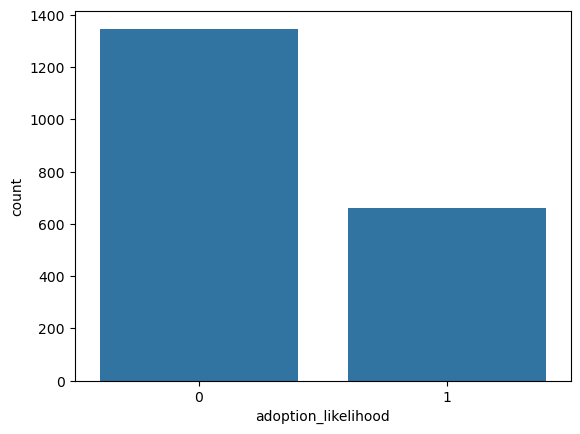

In [23]:
# Step 5: Visualize the distribution of the target variable 'adoption_likelihood' using a bar chart
sns.countplot(x='adoption_likelihood', data=df)


<Axes: xlabel='age_months', ylabel='Count'>

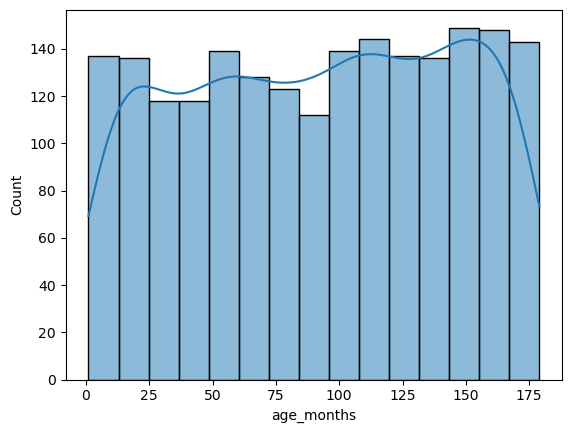

In [24]:
# Step 6: Visualize the distribution of 'age_months' using a histogram
sns.histplot(df['age_months'],bins=15,kde=True)

<Axes: xlabel='adoption_fee', ylabel='Count'>

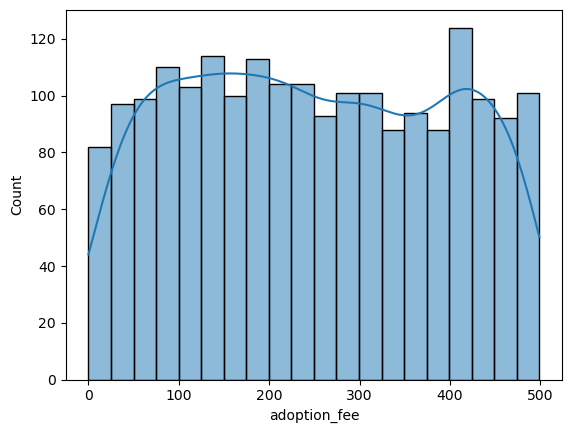

In [25]:
# Step 7: Visualize the distribution of 'adoption_fee' using a histogram
sns.histplot(data=df, x='adoption_fee',kde=True,bins=20)

### Task 2: Data Encoding and Scaling

1. Encode the categorical variables:
    - `'size'`: Encode by mapping it to numbers (e.g., Small=1, Medium=2, Large=3).
    - `'color'`, `'pet_type'`, `'breed'`: Apply one-hot encoding.
<br></br>
3. Scale the numerical features:
    - `'weight_kg'`: MinMax scaling.
    - `'adoption_fee'`: Standard scaling.
<br></br>
4. Display the first few rows of the updated dataset.

In [26]:
# Step 1: Encode the categorical variables

# Encode 'size' by mapping it to numbers (e.g., Small=1, Medium=2, Large=3).
df['size_num']=df['size'].map({'Small': 1, 'Medium':2, 'Large': 3})
df.drop('size',axis=1,inplace=True)


# Encode 'color', 'pet_type' and 'breed' using one-hot encoding
df=pd.get_dummies(data=df,columns=['color', 'pet_type','breed'],drop_first=True)
df.head()

,age_months,weight_kg,vaccinated,health_condition,timein_shelter_days,adoption_fee,previous_owner,adoption_likelihood,size_num,color_Brown,...,color_White,pet_type_Cat,pet_type_Dog,pet_type_Rabbit,breed_Labrador,breed_Parakeet,breed_Persian,breed_Poodle,breed_Rabbit,breed_Siamese
0,131,5.039768,1,0,27,140,0,0,3,False,...,False,False,False,False,False,True,False,False,False,False
1,73,16.086727,0,0,8,235,0,0,3,False,...,True,False,False,True,False,False,False,False,True,False
2,136,2.076286,0,0,85,385,0,0,2,False,...,False,False,True,False,False,False,False,False,False,False
3,97,3.339423,0,0,61,217,1,0,1,False,...,True,False,False,False,False,True,False,False,False,False
4,123,20.498100,0,0,28,14,1,0,3,False,...,False,False,False,True,False,False,False,False,True,False


In [30]:
# Step 2: Scale the numerical features
from sklearn.preprocessing import MinMaxScaler, StandardScaler
# Scale 'weight_kg' using MinMaxScaler
min_max_scaler=MinMaxScaler()
df['weight_kg']=min_max_scaler.fit_transform(df[['weight_kg']])

# Scale 'adoption_fee' using StandardScaler
std_scaler= StandardScaler()
df['adoption_fee']=std_scaler.fit_transform(df[['adoption_fee']])



In [31]:
# step3: Display the first few rows of the updated dataset.

df.head()

,age_months,weight_kg,vaccinated,health_condition,timein_shelter_days,adoption_fee,previous_owner,adoption_likelihood,size_num,color_Brown,...,color_White,pet_type_Cat,pet_type_Dog,pet_type_Rabbit,breed_Labrador,breed_Parakeet,breed_Persian,breed_Poodle,breed_Rabbit,breed_Siamese
0,131,0.138783,1,0,27,-0.764025,0,0,3,False,...,False,False,False,False,False,True,False,False,False,False
1,73,0.520009,0,0,8,-0.098998,0,0,3,False,...,True,False,False,True,False,False,False,False,True,False
2,136,0.036514,0,0,85,0.951044,0,0,2,False,...,False,False,True,False,False,False,False,False,False,False
3,97,0.080105,0,0,61,-0.225003,1,0,1,False,...,True,False,False,False,False,True,False,False,False,False
4,123,0.672244,0,0,28,-1.646060,1,0,3,False,...,False,False,False,True,False,False,False,False,True,False


### Task 3: Model Training Using Decision Tree

1. Select the features and the target variable `('adoption_likelihood')` for modeling.
2. Split the data into training and test sets with a test size of 30%.
3. Initialize and train a Decision Tree Classifier using the training data.
4. Print the model's accuracy score on the test data.
5. Make predictions on the test set.
6. Evaluate the model using a classification report and confusion matrix.
7. Visualize the confusion matrix.
8. Visualize the decision tree structure.

In [32]:
# Step 1: Select the features and the target variable for modeling
from sklearn.model_selection import train_test_split

X=df.drop("adoption_likelihood", axis=1)
y=df['adoption_likelihood']
# Step 2: Split the data into training and test sets with a test size of 30%
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=25)

In [33]:
# Step 3: Initialize and train a Decision Tree Classifier using the training data
from sklearn.tree import DecisionTreeClassifier

model=DecisionTreeClassifier()

model.fit(X_train,y_train)

# Step 4: Print the model's accuracy score on the test data
model.score(X_test,y_test)


0.8772802653399668

In [34]:
# Step 5: Make predictions on the test set
from sklearn.metrics import classification_report, confusion_matrix

y_pred=model.predict(X_test)

# Step 6: Evaluate the model using a classification report and confusion matrix
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.92      0.90      0.91       408
           1       0.80      0.83      0.81       195

    accuracy                           0.88       603
   macro avg       0.86      0.86      0.86       603
weighted avg       0.88      0.88      0.88       603



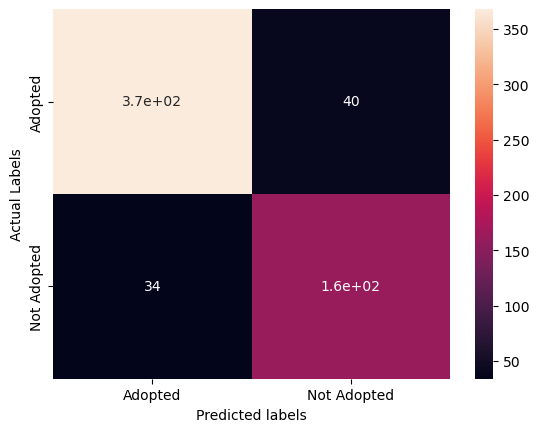

In [35]:
# Step 7: Visualize the confusion matrix
cm=confusion_matrix(y_test,y_pred)

classes=['Adopted',"Not Adopted"]

sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
plt.xlabel("Predicted labels")
plt.ylabel("Actual Labels")
plt.show()


### Task 4: Experiment with Hyperparameters in Decision Tree

1. Train the Decision Tree model with the following parameters:
   - criterion='entropy'
   - max_depth=5
   - min_samples_split=10
   - min_samples_leaf=5

Learn about these parameters here: [DecisionTreeClassifier Parameters](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

--------------------------------------------------------------------------------------------------------------------------------------------------------


2. Print the model's accuracy score on the test data.
3. Evaluate the model using a classification report and confusion matrix.
4. Visualize the confusion matrix.
5. Visualize the decision tree structure.

In [40]:
# Step 1: Train the Decision Tree model with specified hyperparameters
mod=DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=10, min_samples_leaf=5)
mod.fit(X_train,y_train)

# Step 2: Print the model's accuracy score on the test data
print(f'Model\'s accuracy : {mod.score(X_test,y_test)}')

# Step 3: Make predictions on the test set
mod_pred=mod.predict(X_test)

# Step 4: Evaluate the model using a classification report and confusion matrix
rep=classification_report(y_test,mod_pred)
print(rep)


Model's accuracy : 0.9170812603648425
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       408
           1       0.91      0.82      0.86       195

    accuracy                           0.92       603
   macro avg       0.92      0.89      0.90       603
weighted avg       0.92      0.92      0.92       603



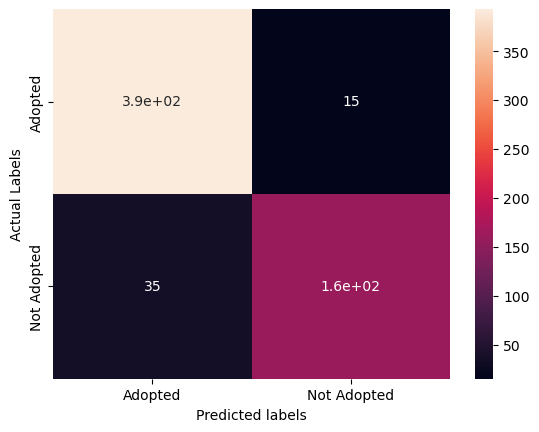

In [41]:
# Step 5: Visualize the confusion matrix
cm=confusion_matrix(y_test,mod_pred)

classes=['Adopted',"Not Adopted"]

sns.heatmap(cm,annot=True,xticklabels=classes,yticklabels=classes)
plt.xlabel("Predicted labels")
plt.ylabel("Actual Labels")
plt.show()


In [44]:
# Step 6: Visualize the decision tree
from sklearn.tree import export_text
classification_tree= export_text(mod,feature_names=list(X.columns))
print(classification_tree)

|--- vaccinated <= 0.50
|   |--- age_months <= 22.50
|   |   |--- size_num <= 2.50
|   |   |   |--- size_num <= 1.50
|   |   |   |   |--- pet_type_Dog <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- pet_type_Dog >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- size_num >  1.50
|   |   |   |   |--- health_condition <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- health_condition >  0.50
|   |   |   |   |   |--- class: 0
|   |   |--- size_num >  2.50
|   |   |   |--- class: 0
|   |--- age_months >  22.50
|   |   |--- breed_Labrador <= 0.50
|   |   |   |--- adoption_fee <= 0.61
|   |   |   |   |--- adoption_fee <= 0.57
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- adoption_fee >  0.57
|   |   |   |   |   |--- class: 0
|   |   |   |--- adoption_fee >  0.61
|   |   |   |   |--- age_months <= 28.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- age_months >  28.00
|   |   |   |   |   |--- class: 0
|   |   |--- breed_Labrador >  0.50
| 